In [1]:
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.core.diffusion import Reaction_Diffusion
import seaborn as sns
import joblib
import numpy as np
import pandas as pd
import math
from copy import deepcopy
import re

from kinetic_model.simulation.reaction_list_creator import (
    make_reaction_list_chemisorp_simplified,
    prepare_constants_chemisorp_simplified
)


class ReactorLog(ReactorSimulationChemisorptionSimplified):
    """
    A class to handle the reactor stream simulation.
    Inherits from ReactorSimulationChemisorption.
    """
    def run(self, build_solver: bool = True):
        if build_solver:
            self.solver = self._build_solver()
        times  = np.logspace(1e-5, np.log10(self.time_hours * 3600), self.n_steps)
        self._result = self.solver.solve(
            initial_concs_dict=self.initial_concs,
            time_points=times
        )
        # self._result.index = times
        # final distribution
        dist = self._calc_distribution(self._result)
        # time-series probabilities
        olefin_cols = [c for c in self._result.columns if re.match(r'C\d+(_out)?$', c)]
        ts = self._result[olefin_cols]
        return dist, ts


def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)


def check_convergance(ts, error_threshold=1e-2):
    distr = time_distribution(ts.reset_index(names=['time']))
    is_converged = bool(tail_slope_prob_per_n(distr, tail_frac=0.10).slope.abs().max() < error_threshold)
    if is_converged:
        return True
    return False

In [87]:
N = 16
temperature = 480  # Kelvin
pressure = 1  # bar
steps = 1e3
time = 1e6
diffusion = False  # Set to False to disable diffusion

c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorLog(
    N=N,
    T=temperature,
    pressure=pressure,
    L=1000,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-3, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()

def max_constant(reactions):
    return np.max([i[1:] for i in reactions])

def normilize_constants(reactions, r_max=1e6):
    factor = r_max/max_constant(reactions)
    if factor >=1:
        factor = 1
    for i in range(len(reactions)):
        reactions[i] = (reactions[i][0], reactions[i][1] * factor, reactions[i][2] * factor)
    return factor

factor = normilize_constants(reactor._reactions, r_max=1e10)
reactor.time_hours /= factor

for i in reactor._reactions:
    print('{:35s} {:5.2e} {:5.2e}'.format(*i))

distr, ts = reactor.run(build_solver=False)
ts.index = ts.index / 3600 * factor

CatC2(C2) + C2 <-> CatC4(C2)        8.82e+03 5.16e+01
CatC4(C2) + C2 <-> CatC6(C2)        2.54e+04 1.52e+01
CatC6(C2) + C2 <-> CatC8(C2)        1.07e+04 5.32e+01
CatC8(C2) + C2 <-> CatC10(C2)       1.07e+04 5.32e+01
CatC10(C2) + C2 <-> CatC12(C2)      1.07e+04 5.32e+01
CatC12(C2) + C2 <-> CatC14(C2)      1.07e+04 5.32e+01
CatC14(C2) + C2 <-> CatC16(C2)      1.07e+04 5.32e+01
CatC4(C2) + C2 <-> CatC2(C2) + C4   2.26e+09 2.42e+08
CatC6(C2) + C2 <-> CatC2(C2) + C6   1.55e+09 2.42e+08
CatC8(C2) + C2 <-> CatC2(C2) + C8   1.55e+09 2.42e+08
CatC10(C2) + C2 <-> CatC2(C2) + C10 1.55e+09 2.42e+08
CatC12(C2) + C2 <-> CatC2(C2) + C12 1.55e+09 2.42e+08
CatC14(C2) + C2 <-> CatC2(C2) + C14 1.55e+09 2.42e+08
CatC16(C2) + C2 <-> CatC2(C2) + C16 1.55e+09 2.42e+08


(-0.1, 1.0)

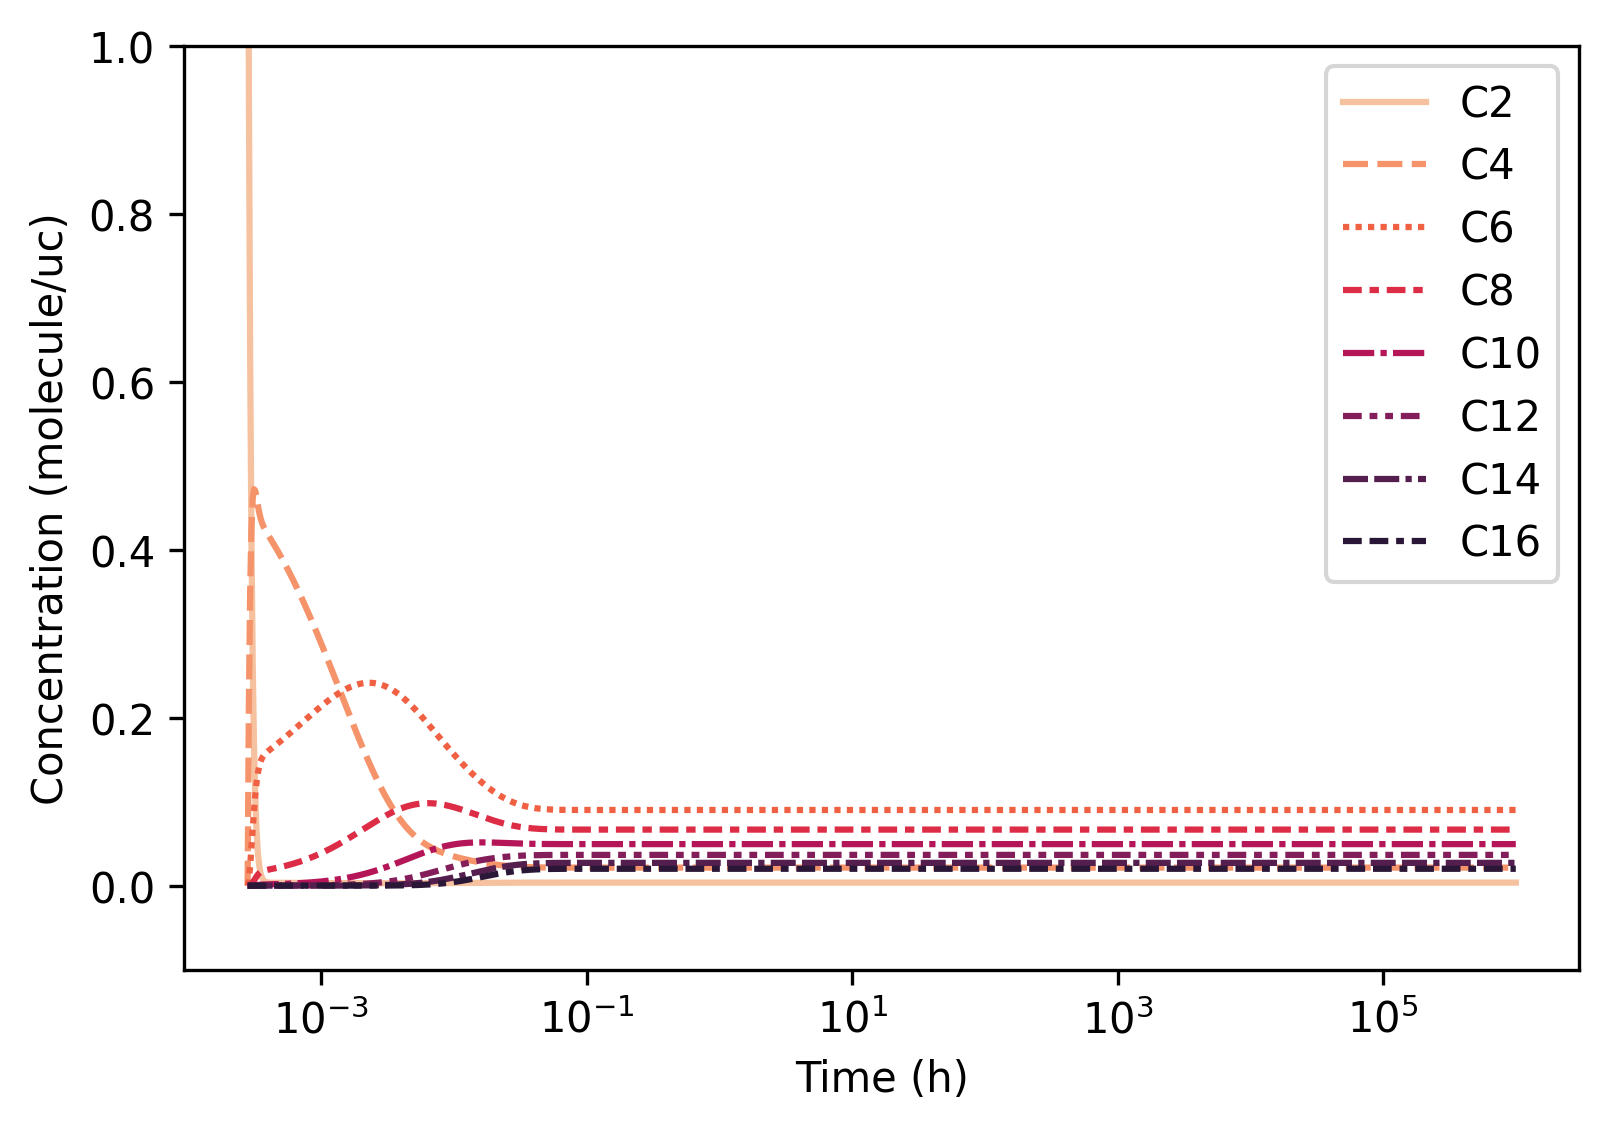

In [88]:
import matplotlib.pyplot as plt
ts = ts.loc[:, [f'C{n}' for n in range(2, N+1, 2)]]
fig, axs = plt.subplots(1, 1, figsize=(6, 4), dpi=300)
sns.lineplot(data=ts, ax=axs, palette='rocket_r')
axs.set_xlabel('Time (h)')
axs.set_ylabel('Concentration (molecule/uc)')
axs.set_xscale('log')
axs.set_ylim(-0.1, 1.0)

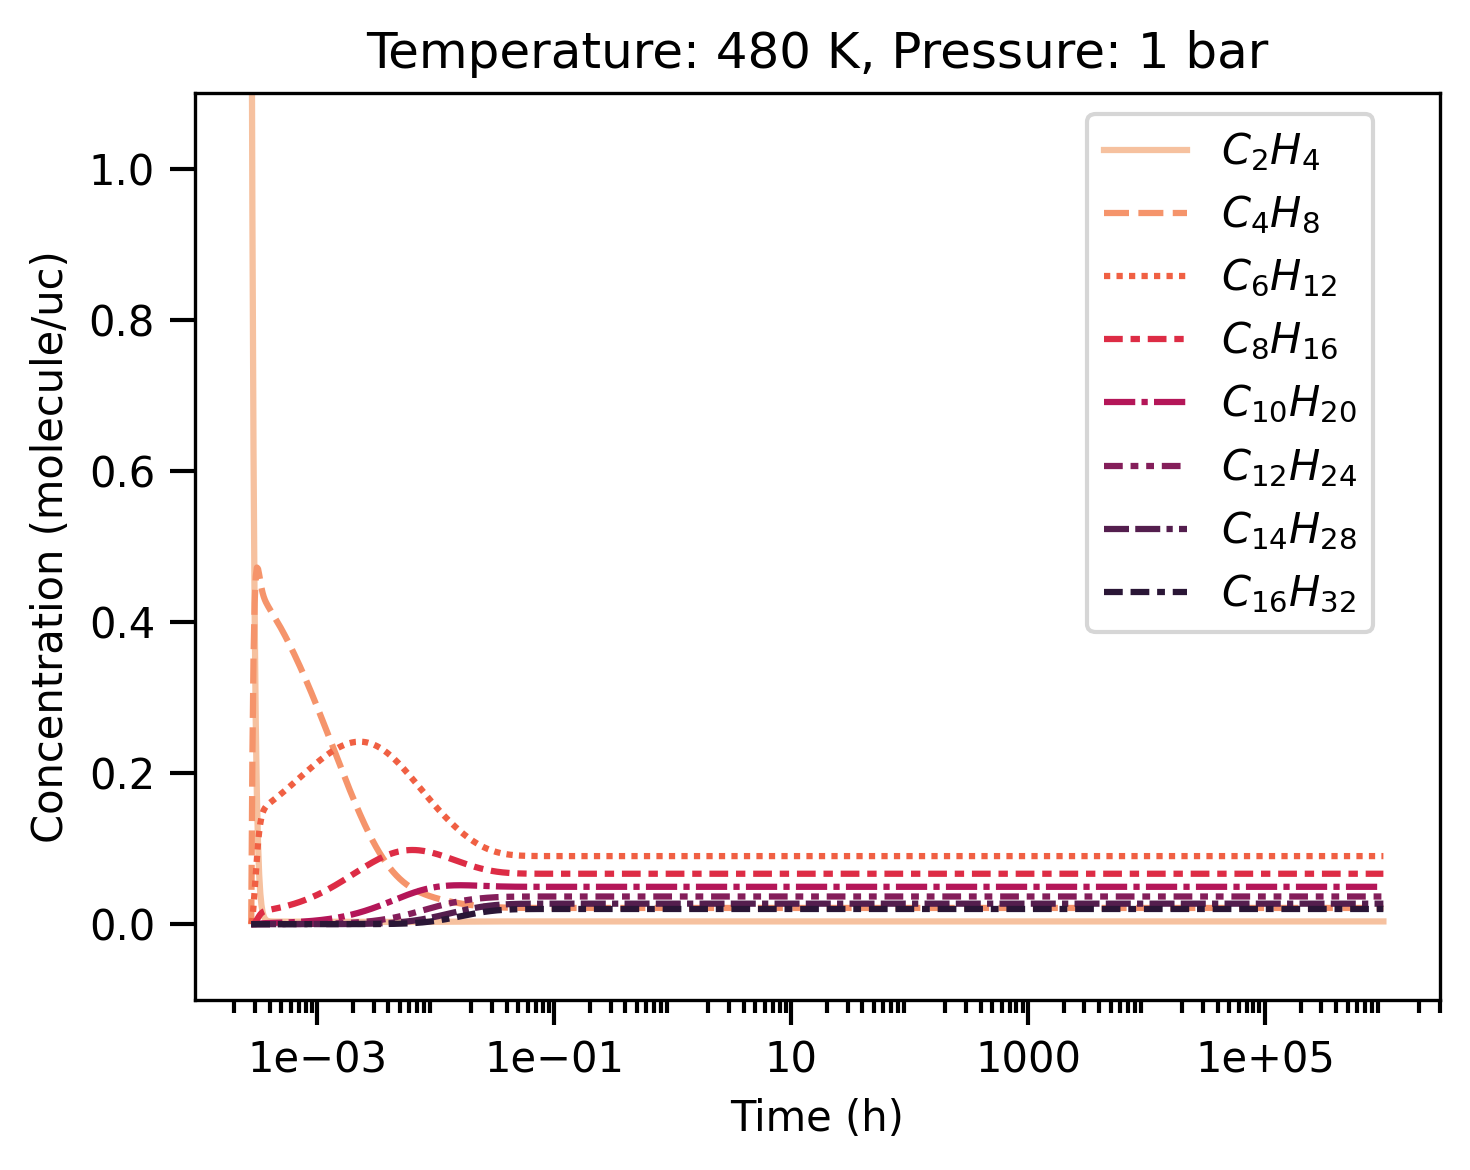

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, LogFormatter

# your existing code
ts = ts.loc[:, [f'C{n}' for n in range(2, N+1, 2)]]
fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
sns.lineplot(data=ts, ax=ax, palette='rocket_r')

ax.set_xlabel('Time (h)')
ax.set_ylabel('Concentration (molecule/uc)')
ax.set_xscale('log')
ax.set_ylim(-0.1, 1.1)
ax.set_title(f'Temperature: {temperature} K, Pressure: {pressure} bar')
# add beautiful log ticks
ax.xaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=100))
ax.xaxis.set_major_formatter(LogFormatter(base=10, labelOnlyBase=False))

# optional: make them stand out
ax.tick_params(which='both', width=1)
ax.tick_params(which='major', length=6)
ax.tick_params(which='minor', length=3)
handles, labels = ax.get_legend_handles_labels()
labels = [f'$C_{{{n}}}H_{{{2*n}}}$' for n in range(2, N+1, 2)]
ax.legend(handles, labels, title='', bbox_to_anchor=(0.7, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [8]:
# Assume each element in reactor._reactions is (reaction_str, kf, kb)

print(r"\begin{table}[h]")
print(r"\centering")
print(r"\begin{tabular}{lcc}")
print(r"\hline")
print(r"Reaction & $k_\mathrm{f}$ & $k_\mathrm{b}$ \\")
print(r"\hline")

for reaction, kf, kb in reactor._reactions:
    print(f"{reaction} & {kf:.2e} & {kb:.2e} \\\\")

print(r"\hline")
print(r"\end{tabular}")
print(r"\caption{Forward and backward rate constants for all elementary reactions.}")
print(r"\label{tab:rates}")
print(r"\end{table}")


\begin{table}[h]
\centering
\begin{tabular}{lcc}
\hline
Reaction & $k_\mathrm{f}$ & $k_\mathrm{b}$ \\
\hline
CatC2(C2) + C2 <-> CatC4(C2) & 2.22e+03 & 2.44e+00 \\
CatC4(C2) + C2 <-> CatC6(C2) & 7.59e+03 & 7.24e-01 \\
CatC6(C2) + C2 <-> CatC8(C2) & 2.85e+03 & 2.40e+00 \\
CatC8(C2) + C2 <-> CatC10(C2) & 2.85e+03 & 2.40e+00 \\
CatC10(C2) + C2 <-> CatC12(C2) & 2.85e+03 & 2.40e+00 \\
CatC12(C2) + C2 <-> CatC14(C2) & 2.85e+03 & 2.40e+00 \\
CatC14(C2) + C2 <-> CatC16(C2) & 2.85e+03 & 2.40e+00 \\
CatC4(C2) + C2 <-> CatC2(C2) + C4 & 2.27e+08 & 2.83e+07 \\
CatC6(C2) + C2 <-> CatC2(C2) + C6 & 1.26e+08 & 2.83e+07 \\
CatC8(C2) + C2 <-> CatC2(C2) + C8 & 1.26e+08 & 2.83e+07 \\
CatC10(C2) + C2 <-> CatC2(C2) + C10 & 1.26e+08 & 2.83e+07 \\
CatC12(C2) + C2 <-> CatC2(C2) + C12 & 1.26e+08 & 2.83e+07 \\
CatC14(C2) + C2 <-> CatC2(C2) + C14 & 1.26e+08 & 2.83e+07 \\
CatC16(C2) + C2 <-> CatC2(C2) + C16 & 1.26e+08 & 2.83e+07 \\
\hline
\end{tabular}
\caption{Forward and backward rate constants for all elementary 

In [14]:
ts.to_pickle(f'files/processed/ts_century_run_c16_temperature_{int(temperature)}_pressure_{int(pressure)}.pkl')

In [13]:
def get_energies(temperature, pressure, N=8):
    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )

    barriers = energy_barriers.get_energy_barriers()
    
    energies = [0, 
                barriers['deelimination_di'] - barriers['elimination_di'] \
                + barriers['insertion_tri'] - barriers['deinsertion_tri'] \
                + barriers['elimination_tri'] - barriers['deelimination_tri'] \
                ]

    energies = energies + [
                            
            energies[1]    + barriers['deelimination_tri'] - barriers['elimination_tri'] \
                + barriers['insertion_tetra'] - barriers['deinsertion_tetra'] \
                + barriers['elimination_tetra'] - barriers['deelimination_tetra']
    ]

    for _ in range(8, N, 2):
        energies.append(energies[-1] + energies[-1] - energies[-2])

    return energies


def state_probabilities(energies_kjmol, temperature):
    """
    Calculate probabilities of each state using the Boltzmann distribution.

    Parameters
    ----------
    energies_kjmol : array-like
        Energies of states in kJ/mol.
    temperature : float
        Temperature in Kelvin.

    Returns
    -------
    list of float
        Probabilities of each state (sum to 1).
    """
    R = 8.314462618  # J/(mol·K)
    energies_jmol = np.array(energies_kjmol) * 1e3  # convert kJ/mol to J/mol
    boltzmann_factors = np.exp(-energies_jmol / (R * temperature))
    Z = np.sum(boltzmann_factors)
    probabilities = boltzmann_factors / Z
    return probabilities.tolist()


def concentrations(energies_kjmol, temperature):
    probabilities = state_probabilities(energies_kjmol, temperature)
    for cnt, i in enumerate(probabilities):
        probabilities[cnt] = i / ((cnt + 2))
    probabilities = np.array(probabilities)
    probabilities /= probabilities.sum()
    return probabilities

energies = get_energies(600, 1, 16)

probabilities = state_probabilities(energies, 600)
probabilities

[0.05771309472927585,
 0.0734018350674889,
 0.09560995361244705,
 0.12453725743190745,
 0.16221667203739826,
 0.21129619544798897,
 0.2752249916734934]

In [36]:
from tqdm import tqdm

boltzman_distr = []

Temperatures = np.linspace(300, 600, 21)
Pressures = np.linspace(1, 50, 11)

N = 16

with tqdm(total=len(Temperatures) * len(Pressures)) as pbar:
    for temperature in Temperatures:
        for pressure in Pressures:
            energies = get_energies(temperature, pressure, N)
            distr = state_probabilities(energies, temperature)
            distr = distr + [temperature, pressure]
            boltzman_distr.append(distr)
            pbar.update(1)

boltzman_distr_df = pd.DataFrame(boltzman_distr, columns=[f'C{i}' for i in range(4, 17, 2)] + ['temperature', 'pressure'])
boltzman_distr_df = pd.melt(boltzman_distr_df, id_vars=['temperature', 'pressure'])
boltzman_distr_df.head()

100%|██████████| 231/231 [01:29<00:00,  2.59it/s]


,temperature,pressure,variable,value
0,300.0,1.0,C4,2.438645e-50
1,300.0,5.9,C4,5.781679e-55
2,300.0,10.8,C4,1.536843e-56
3,300.0,15.7,C4,1.628462e-57
4,300.0,20.6,C4,3.191354e-58


In [14]:
def get_energies(temperature, pressure):
    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )

    barriers = energy_barriers.get_energy_barriers()
    profile = energy_barriers.get_energy_profile()

    energies = [0, 
                barriers['deelimination_di'] - barriers['elimination_di'] \
                + barriers['insertion_tri'] - barriers['deinsertion_tri'] \
                + barriers['elimination_tri'] - barriers['deelimination_tri'] \
                ]

    energies = energies + [       
            energies[1]    + barriers['deelimination_tri'] - barriers['elimination_tri'] \
                + barriers['insertion_tetra'] - barriers['deinsertion_tetra'] \
                + barriers['elimination_tetra'] - barriers['deelimination_tetra']
    ]
    energies2 = [profile['1p'], profile['1pp'], profile['1ppp']]
    energies2 = [i - profile['1p'] for i in energies2]
    return energies, energies2

for temperature in [300, 360, 450, 600]:
    for pressure in [1, 20, 50]:
        energies, energies2 = get_energies(temperature, pressure)
        for i in range(len(energies)):
            dE = np.abs(energies[i] - energies2[i])
            if dE > 1e-6:
                print(temperature, pressure, i, energies[i], energies2[i], dE)

In [17]:
get_energies(300, 1)

([0, -47.695576064308284, -95.14602201710268],
 [0.0, -47.6955760643083, -95.1460220171027])

In [39]:
df = boltzman_distr_df.copy()
df['n'] = df['variable'].str.extract(r'C(\d+)').astype(int)
df['probability'] = df['value']
# remove n=2
df = df[df.n != 2].copy()

# expectation terms
df['exp_n']  = df['probability'] * df['n']
df['exp_n2'] = df['probability'] * (df['n'] ** 2)

# group by and aggregate
df_grouped = (df.groupby(
        ['temperature', 'pressure'],
        as_index=False
    )
    .agg(expected_n=('exp_n','sum'),
         expected_n2=('exp_n2','sum'))
)

# variance and standard deviation
df_grouped['variance_n'] = df_grouped['expected_n2'] - df_grouped['expected_n']**2
df_grouped['std_n'] = df_grouped['variance_n']**0.5
df_grouped['coefficient_variance'] = df_grouped.std_n/df_grouped.expected_n
# df_grouped = df_grouped[df.coefficient_variance < ]
df_grouped.coefficient_variance.describe(), df_grouped.expected_n.describe()
# df_grouped.to_pickle('files/distr.pkl')

(count    231.000000
 mean       0.007765
 std        0.025130
 min        0.000001
 25%        0.000083
 50%        0.001149
 75%        0.007311
 max        0.307722
 Name: coefficient_variance, dtype: float64,
 count    231.000000
 mean      15.958507
 std        0.293625
 min       11.989862
 25%       15.993188
 50%       15.999831
 75%       15.999999
 max       16.000000
 Name: expected_n, dtype: float64)

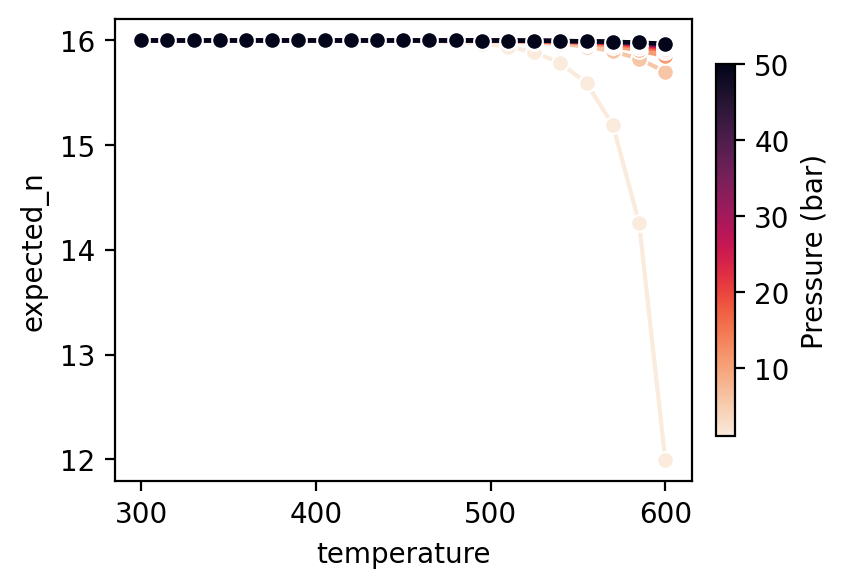

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 1, figsize=(4, 3), dpi=200)
cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

sns.lineplot(
    data=df_grouped,
    x='temperature', y='expected_n', hue='pressure',
    marker='o', ax=axs,
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)
axs.legend_.remove()
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

In [45]:
boltzman_distr_df.to_pickle('files/processed/boltzman_distr_071025_16.pkl')
df_grouped.to_pickle('files/processed/boltzman_distr_summary_071025_16.pkl')